## PCA and Text Analysis

This assignment involves processing real e-mails, some of which are scams. 

(Fair warning: Some of these scam e-mails have offensive content. If you start reading the e-mail text or the token data, you might read something offensive. If that's a problem, feel free to e-mail us, and we can talk about it and discuss how to proceed with alternative tasks.)

In [19]:
pip install fastparquet


Defaulting to user installation because normal site-packages is not writeable
You should consider upgrading via the '/Library/Developer/CommandLineTools/usr/bin/python3 -m pip install --upgrade pip' command.
Note: you may need to restart the kernel to use updated packages.


**Q1.**

**Tokens**: The individual words or symbols that create text data like emails. Natural Language Processing is primarily about analyzing the frequency and co-occurrence of tokens.

We aggregated all the emails into a single vector, and removed the punctuation and very common words (e.g. "the"). Run the below code chunk to open it, and use the Counter class to look at the most common words:

In [27]:
import pickle

with open('data/all_tokens.pickle', 'rb') as file:
    all_tokens = pickle.load(file)
    
from collections import Counter
token_count = Counter(all_tokens)
token_freq = token_count.most_common()

Plot a histogram of the occurrences of tokens. 
What do you notice about the frequency of occurrence of different tokens? How does it look?

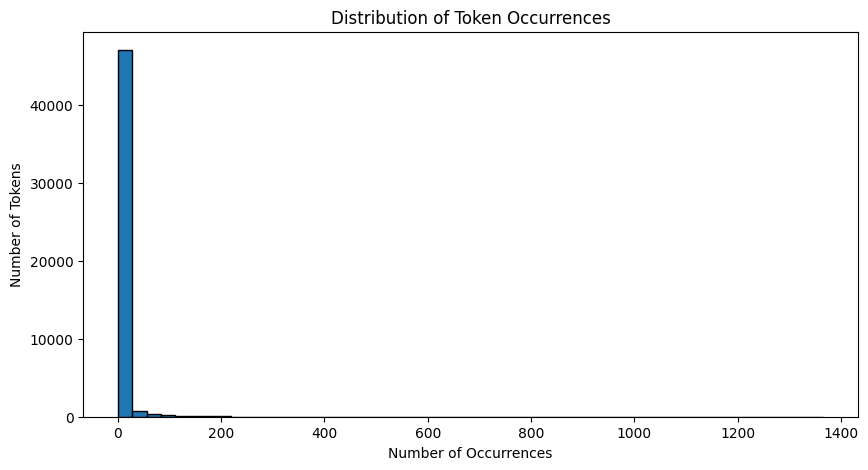

In [ ]:

occurrences = list(token_count.values())

plt.figure(figsize=(10, 5))
plt.hist(occurrences, bins=50, edgecolor='black')

plt.title('Distribution of Token Occurrences')
plt.xlabel('Number of Occurrences')
plt.ylabel('Number of Tokens')
plt.show()

# Most tokens occur only a few times, while relatively few occur very often.
# The distribution is right-skewed, with a long tail toward higher occurrence counts.
#This shows certain words are used very frequently, while many others are used rarely.

**Q2.** 

Load `Phishing_clean.parquet`. This is the text from the e-mails broken into the most common 2,711 tokens and one-hot-encoded as features/covariates. So each row is an e-mail, the `Email Type` takes the value 1 if it's a scam and 0 otherwise, and every other column is a word or symbol that occurs in at least 15 e-mails.

1. Perform an 80/20 train-test split of the data.
2. Run a regression of $y$ on the one-hot-encoded emails. What is the $R^2$ on the test set? On the training set?
3. What words have the largest coefficients in absolute value and most strongly influence predictions? 

In [ ]:
%pip install scikit-learn 
from sklearn.linear_model import LinearRegression
from sklearn.model_selection import train_test_split

In [ ]:
import pandas as pd
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from collections import Counter
from sklearn.model_selection import train_test_split
from sklearn.linear_model import LinearRegression
from sklearn.metrics import r2_score
from sklearn.decomposition import PCA

data = pd.read_parquet("data/Phishing_clean.parquet")

print(data.shape)
print(data.head())
print(data.columns)

x = data.drop(columns=["Email Type"])
y = data["Email Type"]

X_train, X_test, y_train, y_test = train_test_split(
    x,
    y,
    test_size=0.20,
    random_state=42
)

print(X_train.shape)
print(X_test.shape)

model = LinearRegression()
model.fit(X_train, y_train)

y_train_pred = model.predict(X_train)
y_test_pred = model.predict(X_test)

train_r2 = r2_score(y_train, y_train_pred)
test_r2 = r2_score(y_test, y_test_pred)
print("Train R^2:", train_r2)
print("Test R^2:", test_r2)

coefficients = pd.Series(model.coef_, index=x.columns)
coefficients = coefficients.reindex(
    coefficients.abs().sort_values(ascending=False).index)
print('this is the coefficients:', coefficients)
#the words with the largest coefficients are the most important for predicting the email type.
#The words with the smallest coefficients are the least important.



**Q3.** 

Take the matrix of one-hot-encoded tokens (the data, less the outcome variable, `Email Type`) and perform a principal components analysis decomposition with two components. Plot the first two principal components in a scatter plot, and hue the points by whether they are a phishing scam or not. Do you notice any patterns?

In [ ]:
X = df.drop(columns=["Email Type"])
y = df["Email Type"]

pca2 = PCA(n_components=2)
X_pca_2 = pca_2.fit_transform(X)

print("Explained variance ratio:", pca2.explained_variance_ratio_)
print("Total variance explained:", pca2.explained_variance_ratio_.sum())

plt.figure(figsize=(9, 6))

sns.scatterplot(
    x=X_pca_2[:, 0],
    y=X_pca_2[:, 1],
    hue=y,
    alpha=0.6
)

plt.xlabel("Principal Component 1")
plt.ylabel("Principal Component 2")
plt.title("PCA of Emails by Email Type")
plt.legend(title="Email Type")
plt.show()

#in the PCA we see that the two principal components do not separate the email types very well.
#This suggests that the linear regression model may not be able to accurately predict the email type based on the features in the dataset.


**Q4.**

Run a linear regression of $y$ on the first 2,610 principal components of $X$. What is the $R^2$ on the training and test sets?
How does this performance compare to the linear regression?

In [ ]:
pca = PCA(n_components=2610)

X_train_pca = pca.fit_transform(X_train)
X_test_pca = pca.transform(X_test)

print("Training shape after PCA:", X_train_pca.shape)
print("Testing shape after PCA:", X_test_pca.shape)

pca_model = LinearRegression()
pca_model.fit(X_train_pca, y_train)

y_train_pca_pred = pca_model.predict(X_train_pca)
y_test_pca_pred = pca_model.predict(X_test_pca)

pca_train_r2 = r2_score(y_train, y_train_pca_pred)
pca_test_r2 = r2_score(y_test, y_test_pca_pred)

print("PCA training R-squared:", pca_train_r2)
print("PCA testing R-squared:", pca_test_r2)

comparison = pd.DataFrame({
    "Model": [
        "Original features",
        "PCA with 2,610 components"
    ],
    "Training R-squared": [
        train_r2,
        pca_train_r2
    ],
    "Testing R-squared": [
        test_r2,
        pca_test_r2
    ]
})

print(comparison)

**Q5.**

Explain briefly in your own words what the advantage is in using the principal components to run this high-dimensional regression, rather than the original data.

In [ ]:
#the advantages of using the PCA model are that you can reduce the size of the dataset to sets of principal components.
#Moreover, this can help reduce the the risks of overfitting, particularly when the number of features is large relative to the number of observations.

---

## *Phase 1: Solution without AI

Complete all questions in the following cells without generative AI. Then commit and push the
notebook before beginning Phase 2.

**Declaration:** I completed this version without generative AI.

**Student(s):** Araceli Soto

**Date:** 10/21/2026

In [ ]:
# Your Phase 1 solution to the problem goes here.
import pickle

with open('data/all_tokens.pickle', 'rb') as file:
    all_tokens = pickle.load(file)
    
from collections import Counter
token_count = Counter(all_tokens)
token_freq = token_count.most_common()
occurrences = list(token_count.values())

plt.figure(figsize=(10, 5))
plt.hist(occurrences, bins=50, edgecolor='black')

plt.title('Distribution of Token Occurrences')
plt.xlabel('Number of Occurrences')
plt.ylabel('Number of Tokens')
plt.show()

# Most tokens occur only a few times, while relatively few occur very often.
# The distribution is right-skewed, with a long tail toward higher occurrence counts.
#This shows certain words are used very frequently, while many others are used rarely.
%pip install scikit-learn 
from sklearn.linear_model import LinearRegression
from sklearn.model_selection import train_test_split
import pandas as pd
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from collections import Counter
from sklearn.model_selection import train_test_split
from sklearn.linear_model import LinearRegression
from sklearn.metrics import r2_score
from sklearn.decomposition import PCA

data = pd.read_parquet("data/Phishing_clean.parquet")

print(data.shape)
print(data.head())
print(data.columns)

x = data.drop(columns=["Email Type"])
y = data["Email Type"]

X_train, X_test, y_train, y_test = train_test_split(
    x,
    y,
    test_size=0.20,
    random_state=42
)

print(X_train.shape)
print(X_test.shape)

model = LinearRegression()
model.fit(X_train, y_train)

y_train_pred = model.predict(X_train)
y_test_pred = model.predict(X_test)

train_r2 = r2_score(y_train, y_train_pred)
test_r2 = r2_score(y_test, y_test_pred)
print("Train R^2:", train_r2)
print("Test R^2:", test_r2)

coefficients = pd.Series(model.coef_, index=x.columns)
coefficients = coefficients.reindex(
    coefficients.abs().sort_values(ascending=False).index)
print('this is the coefficients:', coefficients)
#the words with the largest coefficients are the most important for predicting the email type.
#The words with the smallest coefficients are the least important.
X = df.drop(columns=["Email Type"])
y = df["Email Type"]

pca2 = PCA(n_components=2)
X_pca_2 = pca_2.fit_transform(X)

print("Explained variance ratio:", pca2.explained_variance_ratio_)
print("Total variance explained:", pca2.explained_variance_ratio_.sum())

plt.figure(figsize=(9, 6))

sns.scatterplot(
    x=X_pca_2[:, 0],
    y=X_pca_2[:, 1],
    hue=y,
    alpha=0.6
)

plt.xlabel("Principal Component 1")
plt.ylabel("Principal Component 2")
plt.title("PCA of Emails by Email Type")
plt.legend(title="Email Type")
plt.show()

#in the PCA we see that the two principal components do not separate the email types very well.
#This suggests that the linear regression model may not be able to accurately predict the email type based on the features in the dataset.
pca = PCA(n_components=2610)

X_train_pca = pca.fit_transform(X_train)
X_test_pca = pca.transform(X_test)

print("Training shape after PCA:", X_train_pca.shape)
print("Testing shape after PCA:", X_test_pca.shape)

pca_model = LinearRegression()
pca_model.fit(X_train_pca, y_train)

y_train_pca_pred = pca_model.predict(X_train_pca)
y_test_pca_pred = pca_model.predict(X_test_pca)

pca_train_r2 = r2_score(y_train, y_train_pca_pred)
pca_test_r2 = r2_score(y_test, y_test_pca_pred)

print("PCA training R-squared:", pca_train_r2)
print("PCA testing R-squared:", pca_test_r2)

comparison = pd.DataFrame({
    "Model": [
        "Original features",
        "PCA with 2,610 components"
    ],
    "Training R-squared": [
        train_r2,
        pca_train_r2
    ],
    "Testing R-squared": [
        test_r2,
        pca_test_r2
    ]
})

print(comparison)

## *Phase 2: AI-assisted Revision
Keep Phase 1 frozen.

- **Phase 1 commit SHA ID:** [To be provided]
- **AI tool and model used:** [To be provided]

### *Prompts used

1. [Paste prompt]
2. [Paste follow-up prompt]

### *AI-proposed changes


[Paste the AI's concise numbered list verbatim.]

1. ...
2. ...

### *Evaluation of AI suggestions


| Change | Decision | Reason and verification |
|---|---|---|
| 1 | Accept / modify / reject | ... |
| 2 | Accept / modify / reject | ... |

### *AI-assisted solution in full
After the evaluation of AI suggestions, incorporate the accepted revisions into your Phase 1 solution and provide the final Phase 2 solution in full in the following cells.

In [ ]:
# Your Phase 2 solution to the problem goes here.


### *Reflection on AI assistance
In your own words without generative AI.

[In 150–300 words, describe the main improvements, AI mistakes or limitations, how the final solution was verified, and any remaining concerns.]